# SPARC4-like registration: a bright star leaving a distorted field

Generate an **RA, Dec, flux** catalogue, project it onto an ideal detector, add a constant drift, apply a fixed field distortion, and render simple Gaussian stars with `library.gen_image`. Compare full-image and centered-window registration against the **known displacement at the optical center**. This is one photometric channel, with no polarimetric splitting.

The instrument anchors are a 1024 × 1024 detector and channel-1 scale of [0.339 arcsec/pixel (LNA/COAST)](https://coast.lna.br/home/sparc4/information-for-users). [Schlindwein et al. (2024), §3.1 and Fig. 1](https://sab-astro.org.br/wp-content/uploads/2024/05/WagnerSchlindwein2.pdf) reports distortion growing toward the edges to about 5 arcsec, modeled with a third-order polynomial. Here a **synthetic radial cubic**, with that amplitude at the ideal-field corners, represents the distortion; it is not the measured per-channel calibration.

We deliberately omit realistic noise, aberrations and detector effects. The study isolates geometry and the loss of a dominant star. Run all cells from the `astropop-studies` directory using a kernel with the local Astropop checkout installed. Runtime requires no network.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from astropy.table import Table
from astropy.wcs import WCS
from library.gen_image import gen_image
from astropop.image.register import CrossCorrelationRegister

%matplotlib inline

rng = np.random.default_rng(20261018)
size = 1024
n_frames = 40
n_sources = 120                    # ordinary stars; add one bright star
pixel_scale = 0.339                # arcsec/pixel
corner_distortion_arcsec = 5.0     # synthetic cubic amplitude
bright_flux = 1_000_000.0          # arbitrary linear flux units
sigma = 2.0                       # Gaussian width in pixels
step_xy = np.array([3.0, 0.4])     # apparent ideal-field drift, pixels/frame
margin = 256
window = (slice(margin, size-margin), slice(margin, size-margin))
center_xy = np.full(2, (size-1)/2)
drift_xy = np.arange(n_frames)[:, None] * step_xy

## Sources → drift → distortion → images

The catalogue covers a slightly larger sky area than the detector, so stars enter and leave naturally. The final row is the single very bright star, placed near the upper-right corner. The TAN WCS supplies the initial RA/Dec-to-pixel projection; drift is then a constant displacement on that ideal focal plane.

For ideal position **p**, the distortion is **D(p) = p + k (p − c) |p − c|²**, where **c** is the detector center and **k** sets the corner amplitude. Each star appears at **D(p + drift)**. Applying drift before distortion is essential: shifting an already distorted image would impose the same displacement on every star.

All positions and returned shifts are **(x, y) = (column, row)**. The window is in NumPy **(row slice, column slice)** order. Pixel centers are 0…1023 and detector boundaries are −0.5 and 1023.5.

In [ ]:
# Draw an extended field and turn its ideal positions into an RA/Dec catalogue.
wcs = WCS(naxis=2)
wcs.wcs.crpix = center_xy + 1       # FITS WCS uses one-based reference pixels
wcs.wcs.crval = [280.0, -6.0]       # arbitrary field center, degrees
wcs.wcs.cdelt = [-pixel_scale/3600, pixel_scale/3600]
wcs.wcs.ctype = ['RA---TAN', 'DEC--TAN']

xy = rng.uniform(-150, size+150, (n_sources, 2))
xy = np.vstack([xy, [940.0, 850.0]])
ra, dec = wcs.pixel_to_world_values(xy[:, 0], xy[:, 1])
flux = np.r_[10**rng.uniform(np.log10(2000), np.log10(10000), n_sources), bright_flux]
sources = Table({'ra': ra, 'dec': dec, 'flux': flux})
sources['ra'].unit = 'deg'
sources['dec'].unit = 'deg'
ideal_xy = np.column_stack(wcs.world_to_pixel_values(sources['ra'], sources['dec']))


def distort(xy):
    q = np.asarray(xy) - center_xy
    k = (corner_distortion_arcsec/pixel_scale) / np.linalg.norm(center_xy)**3
    return np.asarray(xy) + k*q*np.sum(q*q, axis=-1)[..., None]


positions = distort(ideal_xy[None, :, :] + drift_xy[:, None, :])
# Track an ideal sky point initially at the optical center. This is an analytic
# benchmark, independent of the source brightnesses and registration results.
expected_xy = distort(center_xy + drift_xy) - distort(center_xy)
exit_ids = np.flatnonzero(positions[:, -1, 0] >= size-0.5)
if not len(exit_ids) or exit_ids[0] == 0:
    raise ValueError('Adjust bright-star position or drift so it exits during the sequence.')
exit_frame = int(exit_ids[0])
print(f'{len(sources)} sources; bright-star center exits in frame {exit_frame} (zero based).')
sources[-5:]

121 sources; bright-star center exits in frame 26 (zero based).


ra,dec,flux
deg,deg,
float64,float64,float64
280.01805762645586,-6.023871169110668,6260.390368739475
279.96328273016917,-6.053789354783841,2023.4157665932537
280.01220278685844,-5.953157285326408,2996.8095837586616
279.97353967066255,-5.9613422251547545,4119.001670255418
279.95942970099526,-5.968123101257284,1000000.0


In [ ]:
images = []
for xy in positions:
    # Omit only stars whose six-sigma footprints cannot reach the detector.
    visible = np.all((xy > -6*sigma) & (xy < size+6*sigma), axis=1)
    image = gen_image((size, size), xy[visible, 0], xy[visible, 1],
                      np.asarray(sources['flux'])[visible],
                      sky=100, rdnoise=0, model='gaussian', sigma=sigma,
                      theta=0, skip_poisson=True)
    images.append(image.astype(np.float32))
images = np.stack(images)
print('Image sequence:', images.shape)

Image sequence: (40, 1024, 1024)


## Compare with the expected central shift

Both methods use the same images and the same **first-frame reference**. Only `window` differs. Astropop's `CrossCorrelationRegister` uses unnormalized correlation (`normalization=None`), so a very bright star can dominate the estimate. `compute_transform(reference, moving).translation` returns the forward **[dx, dy]** displacement; these are the shifts plotted below.

The exact center displacement is not a universal translation for the whole distorted field. It is the benchmark appropriate to this central-region comparison. Partial clipping and disappearance can also spoil correlation without distortion; the experiment should not attribute every jump solely to distortion.

In [ ]:
estimators = {
    'Full image': CrossCorrelationRegister(upsample_factor=20),
    'Centered window': CrossCorrelationRegister(window=window, upsample_factor=20),
}
shifts = {}
for name, estimator in estimators.items():
    shifts[name] = np.vstack([
        [0.0, 0.0],
        *[estimator.compute_transform(images[0], image).translation for image in images[1:]]
    ])
    assert np.isfinite(shifts[name]).all(), name

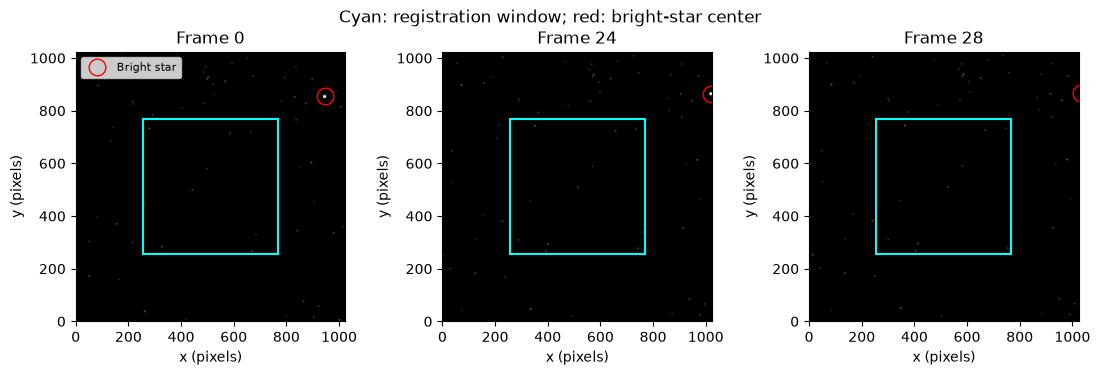

In [ ]:
# One figure establishes the field, the selected window and the star's exit.
snapshots = [0, max(0, exit_frame-2), min(n_frames-1, exit_frame+2)]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout='constrained')
for ax, i in zip(axes, snapshots):
    ax.imshow(images[i], origin='lower', cmap='gray', norm=LogNorm(vmin=100, vmax=4000))
    ax.add_patch(Rectangle((margin, margin), size-2*margin, size-2*margin,
                          fill=False, ec='cyan', lw=1.5))
    ax.plot(*positions[i, -1], 'o', ms=12, mfc='none', mec='red', label='Bright star')
    ax.set(xlim=(-0.5, size-0.5), ylim=(-0.5, size-0.5),
           title=f'Frame {i}', xlabel='x (pixels)', ylabel='y (pixels)')
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Cyan: registration window; red: bright-star center')
plt.show()

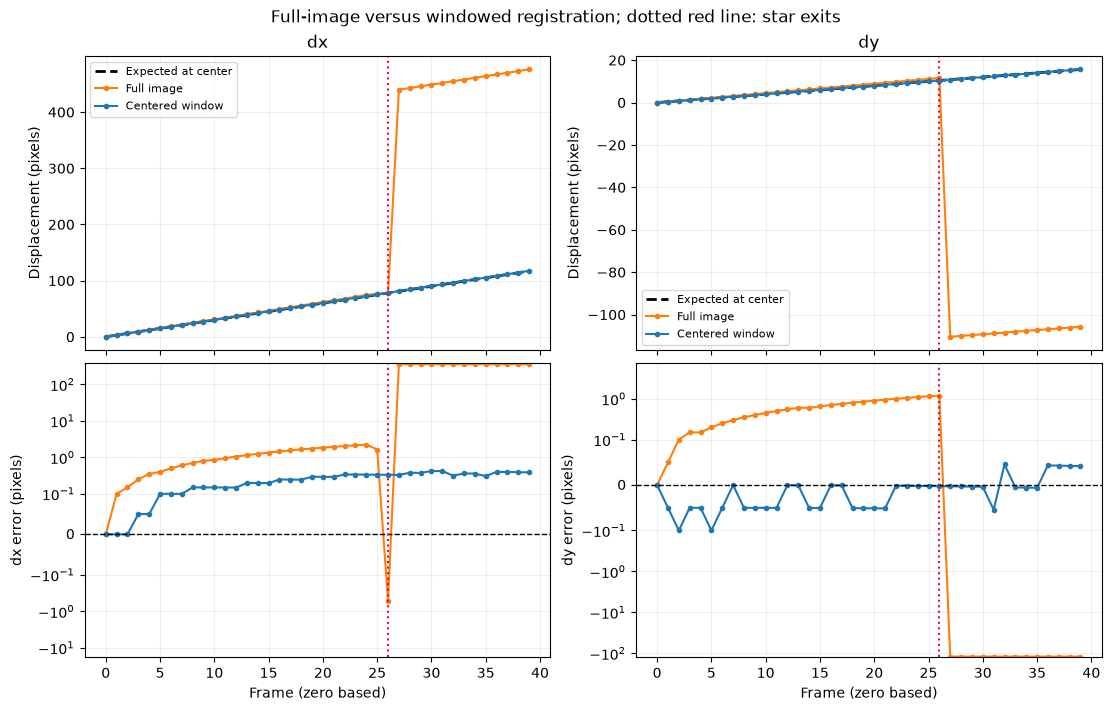

Vector errors relative to the expected center displacement (excluding reference):
Full image        RMSE = 218.799 px; maximum = 379.028 px
Centered window   RMSE = 0.284 px; maximum = 0.422 px


In [ ]:
# One comparison figure: actual shifts above, error against the center below.
frames = np.arange(n_frames)
colors = {'Full image': 'tab:orange', 'Centered window': 'tab:blue'}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout='constrained')
for dim, label in enumerate(('dx', 'dy')):
    axes[0, dim].plot(frames, expected_xy[:, dim], 'k--', lw=2, label='Expected at center')
    for name, values in shifts.items():
        axes[0, dim].plot(frames, values[:, dim], '.-', color=colors[name], label=name)
        axes[1, dim].plot(frames, values[:, dim]-expected_xy[:, dim], '.-',
                          color=colors[name], label=name)
    axes[0, dim].set(title=label, ylabel='Displacement (pixels)')
    axes[0, dim].legend(fontsize=8)
    axes[1, dim].axhline(0, color='k', ls='--', lw=1)
    axes[1, dim].set_yscale('symlog', linthresh=0.1)
    axes[1, dim].set(ylabel=f'{label} error (pixels)', xlabel='Frame (zero based)')
    for ax in axes[:, dim]:
        ax.axvline(exit_frame, color='crimson', ls=':', label='Bright-star center exits')
        ax.grid(alpha=0.2)
fig.suptitle('Full-image versus windowed registration; dotted red line: star exits')
plt.show()

print('Vector errors relative to the expected center displacement (excluding reference):')
for name, values in shifts.items():
    error = np.linalg.norm(values[1:]-expected_xy[1:], axis=1)
    print(f'{name:16s}  RMSE = {np.sqrt(np.mean(error**2)):.3f} px; '
          f'maximum = {error.max():.3f} px')

Read the pre-exit error trend separately from the jump when the bright star disappears. The bottom panels use a **symmetric-log scale**, linear within ±0.1 pixels, so small biases and large outliers remain visible together. No measured shifts are clipped or rejected.

For two simple checks, rerun with `corner_distortion_arcsec = 0` to remove differential distortion, or set `bright_flux = 5000` to remove the star's dominance. The window should contain enough persistent ordinary stars and should not itself be crossed by the bright star. A window estimates a translation for its region; it does not correct optical distortion across the detector.